# 05 · Forecast tomorrow: run the ensemble yourself

## What this notebook shows

This is the "how you would use it" demo. It takes the latest data in the repo, trains the five
models of the ensemble, and makes a real forecast: **how many calls each of the six divisions
should expect on the next day we can forecast**. It takes a few seconds and writes no files.

Everything here calls the project's own code (`ycit440_sim_forecast`); nothing is
re-implemented in the notebook.

### Glossary

| Term | Meaning |
|---|---|
| **Cutoff** | The last day whose counts we know. The city publishes counts about 2 days late. |
| **Issue date** | The day the forecast is made. |
| **Target day** | The day being forecast. |
| **Ensemble member** | One of the five models whose forecasts are averaged. |
| **Expected count** | The forecast: the number of calls to expect on average, not a guarantee. |

## The timeline in plain words

The forecast for a day **D** is made the day before, on **D−1**. But on D−1 we only know the
counts up to **D−3**, because the portal publishes them about two days late. So:

- **D−3**: last day with known counts (the *cutoff*)
- **D−1**: the forecast is made (the *issue date*), 2 days after the cutoff
- **D**: the day being forecast (the *target day*), 3 days after the cutoff

Here we pretend "today" is the day the latest data allows: the last date in the file is the
cutoff, so the issue date is 2 days later and the target day 3 days later.

First, load the tools and point Python at the repo folder.

In [ ]:
import datetime as dt
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from ycit440_sim_forecast.ensemble import Ensemble
from ycit440_sim_forecast.models import ENSEMBLE_CANDIDATES, default_models
from ycit440_sim_forecast.seed import DEFAULT_SEED
from ycit440_sim_forecast.spec import V2_DAILY

# VS Code and nbconvert start notebooks in notebooks/; every path below is relative
# to the repo root.
if not Path("pyproject.toml").exists():
    os.chdir(Path.cwd().parent)

Chart style and a small `check` helper that stops the notebook if something is not what we
expect.

In [ ]:
pl.Config.set_tbl_width_chars(140)
plt.rcParams.update(
    {
        "figure.dpi": 90,
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "axes.titlelocation": "left",
        "axes.titleweight": "bold",
        "legend.frameon": False,
        "font.size": 9,
    }
)
ENS_COLOR = "#2a78d6"
MEMBER_COLORS = ["#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]


def check(cond: bool, msg: str) -> None:
    """Stop the notebook when a number does not match what we expect."""
    if not cond:
        raise AssertionError(msg)

## Load the data and work out the dates

`division_day.parquet` has one row per day and division with the number of calls (`n`). Its
last date is our cutoff. The project's forecast settings (`V2_DAILY`) turn the issue date into
the cutoff and the target day, and we check they agree with the timeline above.

In [ ]:
history = pl.read_parquet("data/processed/division_day.parquet")
last_date = history["date"].max()
issue_date = last_date + dt.timedelta(days=2)
target_day = V2_DAILY.target_start(issue_date)
check(V2_DAILY.cutoff(issue_date) == last_date, "cutoff must be the last data day")
check(target_day == last_date + dt.timedelta(days=3), "target must be cutoff + 3 days")
print(f"Cutoff (last known counts, D-3): {last_date:%a %Y-%m-%d}")
print(f"Issue date (forecast made, D-1): {issue_date:%a %Y-%m-%d}")
print(f"Target day (forecast for, D):    {target_day:%a %Y-%m-%d}")

Cutoff (last known counts, D-3): Thu 2026-09-24
Issue date (forecast made, D-1): Sat 2026-09-26
Target day (forecast for, D):    Sun 2026-09-27


For context, these are the actual counts over the last 7 known days, one column per
division (1 to 6). The forecast should land in a similar range.

In [ ]:
week = history.filter(pl.col("date") > last_date - dt.timedelta(days=7))
week.pivot("DIVISION", index="date", values="n")

date,1,2,3,4,5,6
date,u32,u32,u32,u32,u32,u32
2026-09-18,22,53,49,43,65,62
2026-09-19,20,43,53,44,70,73
2026-09-20,14,55,57,56,53,65
2026-09-21,25,49,63,56,69,58
2026-09-22,24,49,69,53,55,47
2026-09-23,31,54,65,39,52,64
2026-09-24,32,48,79,68,68,69


## Build the five members

`default_models` returns every model the project tested. We keep the five chosen for the
ensemble (`ENSEMBLE_CANDIDATES`): two gradient-boosted tree models (`lgbm_…`), a CatBoost
tree model (`cat_tweedie`), and two smoothing models that follow the weekly pattern
(`ets_weekly`, `topdown_ets`). `DEFAULT_SEED` fixes the randomness so the result is the same
every run.

In [ ]:
members = [m for m in default_models(DEFAULT_SEED) if m.name in ENSEMBLE_CANDIDATES]
check(len(members) == 5, f"expected 5 members, got {[m.name for m in members]}")
print("Members:", ", ".join(m.name for m in members))

Members: lgbm_poisson, lgbm_poisson_raw, cat_tweedie, ets_weekly, topdown_ets


## Train the ensemble

`Ensemble("ens_mean", members, "mean")` wraps the five models; `"mean"` means its forecast is
the plain average of theirs. `.fit` trains every member on all the data up to the cutoff (the
whole file, since it ends at the cutoff).

In [ ]:
start = time.perf_counter()
ens = Ensemble("ens_mean", members, "mean").fit(history, V2_DAILY)
print(f"Trained {len(ens.members)} models in {time.perf_counter() - start:.1f} seconds")

Trained 5 models in 1.3 seconds


## Make the forecast

Ask the ensemble for its forecast on the issue date, and ask each member for its own forecast
too, so we can see what is being averaged. The check confirms the ensemble value really is the
average of the five.

In [ ]:
names = [m.name for m in ens.members]
forecast = ens.predict(history, issue_date, V2_DAILY).rename({"y_pred": "ens_mean"})
for member in ens.members:
    own = member.predict(history, issue_date, V2_DAILY).rename({"y_pred": member.name})
    forecast = forecast.join(own, on="DIVISION")
average = forecast.select(pl.mean_horizontal(names)).to_series()
gap = (forecast["ens_mean"] - average).abs()
check(gap.max() < 1e-9, "the ensemble should equal the mean of its members")

The forecast table: one row per division, each member's forecast, the ensemble (their
average), and the ensemble rounded to whole calls.

In [ ]:
table = forecast.select("DIVISION", *names, "ens_mean").with_columns(
    pl.exclude("DIVISION").round(1),
    calls=pl.col("ens_mean").round().cast(pl.Int64),
)
print(f"Forecast for {target_day:%A %Y-%m-%d}: city total {table['calls'].sum()} calls")
table

Forecast for Sunday 2026-09-27: city total 318 calls


DIVISION,lgbm_poisson,lgbm_poisson_raw,cat_tweedie,ets_weekly,topdown_ets,ens_mean,calls
i64,f64,f64,f64,f64,f64,f64,i64
1,26.6,28.9,26.0,23.5,25.9,26.2,26
2,55.0,54.2,55.3,48.7,55.5,53.7,54
3,60.1,62.2,61.2,60.5,61.7,61.1,61
4,52.7,53.6,53.4,52.2,53.9,53.2,53
5,60.5,60.7,61.8,57.8,60.4,60.2,60
6,63.8,67.7,65.2,62.7,60.3,63.9,64


The same forecast as a chart. Each bar is the ensemble forecast for a division; the coloured
dots are the five members. Where the dots are close together the models agree; where they
spread out, they disagree and the average smooths that out.

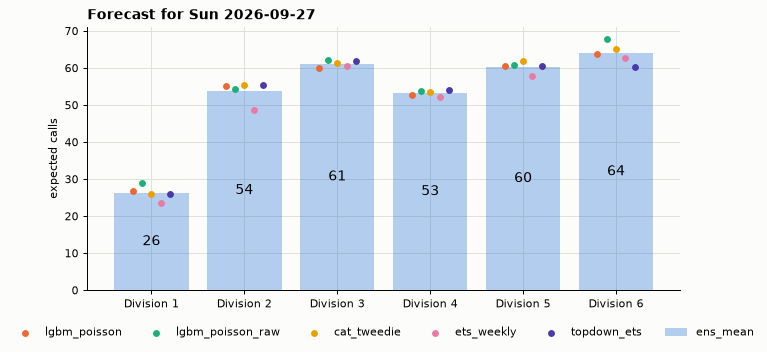

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(forecast.height)
bars = ax.bar(x, forecast["ens_mean"], color=ENS_COLOR, alpha=0.35, label="ens_mean")
ax.bar_label(bars, fmt="%.0f", label_type="center", fontsize=11)
for i, (name, color) in enumerate(zip(names, MEMBER_COLORS, strict=True)):
    ax.scatter(x + (i - 2) * 0.1, forecast[name], c=color, s=20, zorder=3, label=name)
ax.set_xticks(x, [f"Division {d}" for d in forecast["DIVISION"]])
ax.set(ylabel="expected calls", title=f"Forecast for {target_day:%a %Y-%m-%d}")
ax.legend(ncols=6, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

## How to read this forecast

- These are **expected counts**: the number of calls to expect on average for a day like this,
  not a promise. The real number will be higher or lower.
- On the 2025 – 2026 test (notebook 04) the ensemble was off by about **±8 calls per division
  per day** on average (a little less for the quieter Division 1, a little more for the busier
  ones). A forecast of 60 calls means "probably somewhere around 52 to 68".
- The forecast only uses past counts and the calendar. It knows nothing about storms,
  heatwaves, events or other news, so unusual days can miss by much more.
- Volume is not workload: the forecast counts calls, not how long or how hard they are.